# Homework 6

Name: Shanglin Jiang

GitHub Username: sjiang83-corgi

USC ID: 1967702034

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score
from sklearn.metrics import accuracy_score, recall_score, precision_score, balanced_accuracy_score
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from threadpoolctl import threadpool_limits
from xgboost import XGBClassifier

SEED = 552
DATA_DIR = Path("../data")
RESULT_DIR = Path("../results")
RESULT_DIR.mkdir(exist_ok=True)
pd.set_option("display.max_rows", 180)
pd.set_option("display.precision", 6)
plt.rcParams["figure.dpi"] = 110

## 1(a) APS Failure data

In [2]:
def read_aps(filename):
    path = DATA_DIR / filename
    with path.open() as file:
        header_row = next(i for i, line in enumerate(file) if line.startswith("class,"))
    return pd.read_csv(path, skiprows=header_row, na_values="na")

training = read_aps("aps_failure_training_set.csv")
testing = read_aps("aps_failure_test_set.csv")
X_train = training.drop(columns="class")
X_test = testing.drop(columns="class")
y_train = training["class"].map({"neg": 0, "pos": 1}).to_numpy()
y_test = testing["class"].map({"neg": 0, "pos": 1}).to_numpy()
assert X_train.shape == (60000, 170)
assert X_test.shape == (16000, 170)
assert X_train.columns.equals(X_test.columns)
assert set(np.unique(y_train)) == {0, 1}
assert set(np.unique(y_test)) == {0, 1}
display(training.head())
print("Training shape:", training.shape)
print("Test shape:", testing.shape)

,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


Training shape: (60000, 171)
Test shape: (16000, 171)


## 1(b)(i) Missing values

I used the median for the mean or median imputation, nearest-neighbor imputation, and iterative regression-based imputation. This is because many APS measurements are skewed and this approach is very practical for datasets of this size. No rows or features were removed.

Training and test medians are calculated separately as described in footnote 1. Within CV, each training fold and each validation fold are imputed with the medians of that fold’s training data. This is done using the unlabeled validation/test batch distribution as specified in the handout (no validation or test labels are used). SMOTE scaling is fitted to the training fold.

In [3]:
missing_counts = pd.DataFrame({
    "Train missing": X_train.isna().sum(),
    "Test missing": X_test.isna().sum()
})
display(missing_counts)
assert not X_train.isna().all().any()
assert not X_test.isna().all().any()
train_imputer = SimpleImputer(strategy="median")
test_imputer = SimpleImputer(strategy="median")
X_train_filled = train_imputer.fit_transform(X_train)
X_test_filled = test_imputer.fit_transform(X_test)
assert np.isfinite(X_train_filled).all() and np.isfinite(X_test_filled).all()
train_features = pd.DataFrame(X_train_filled, columns=X_train.columns)
missing_counts.to_csv(RESULT_DIR / "missing_counts.csv")

,Train missing,Test missing
aa_000,0,0
ab_000,46329,12363
ac_000,3335,926
ad_000,14861,3981
ae_000,2500,690
af_000,2500,690
ag_000,671,189
ag_001,671,189
ag_002,671,189
ag_003,671,189


## 1(b)(ii) Coefficient of variation

In [4]:
means = train_features.mean()
sample_std = train_features.std(ddof=1)
feature_cv = sample_std / means.replace(0, np.nan)
cv_table = pd.DataFrame({"Mean": means, "Sample SD": sample_std, "CV": feature_cv})
cv_table = cv_table.sort_values("CV", ascending=False)
display(cv_table)
cv_table.to_csv(RESULT_DIR / "feature_cv.csv")
print("Zero-mean features with undefined CV:", means.index[means == 0].tolist())

,Mean,Sample SD,CV
cf_000,1.431075e+05,3.504525e+07,244.887517
co_000,1.433300e+05,3.504525e+07,244.507385
ad_000,1.434383e+05,3.504525e+07,244.322816
cs_009,7.705097e+02,1.833278e+05,237.930554
dh_000,4.392641e+03,5.412441e+05,123.216097
dj_000,3.727133e+01,4.379166e+03,117.494225
ag_000,2.191577e+02,2.036364e+04,92.917755
as_000,1.254079e+02,1.095219e+04,87.332500
ay_009,1.149620e+03,9.741156e+04,84.733735
ak_000,9.076607e+02,7.299859e+04,80.424975


Zero-mean features with undefined CV: []


## 1(b)(iii) Correlation matrix

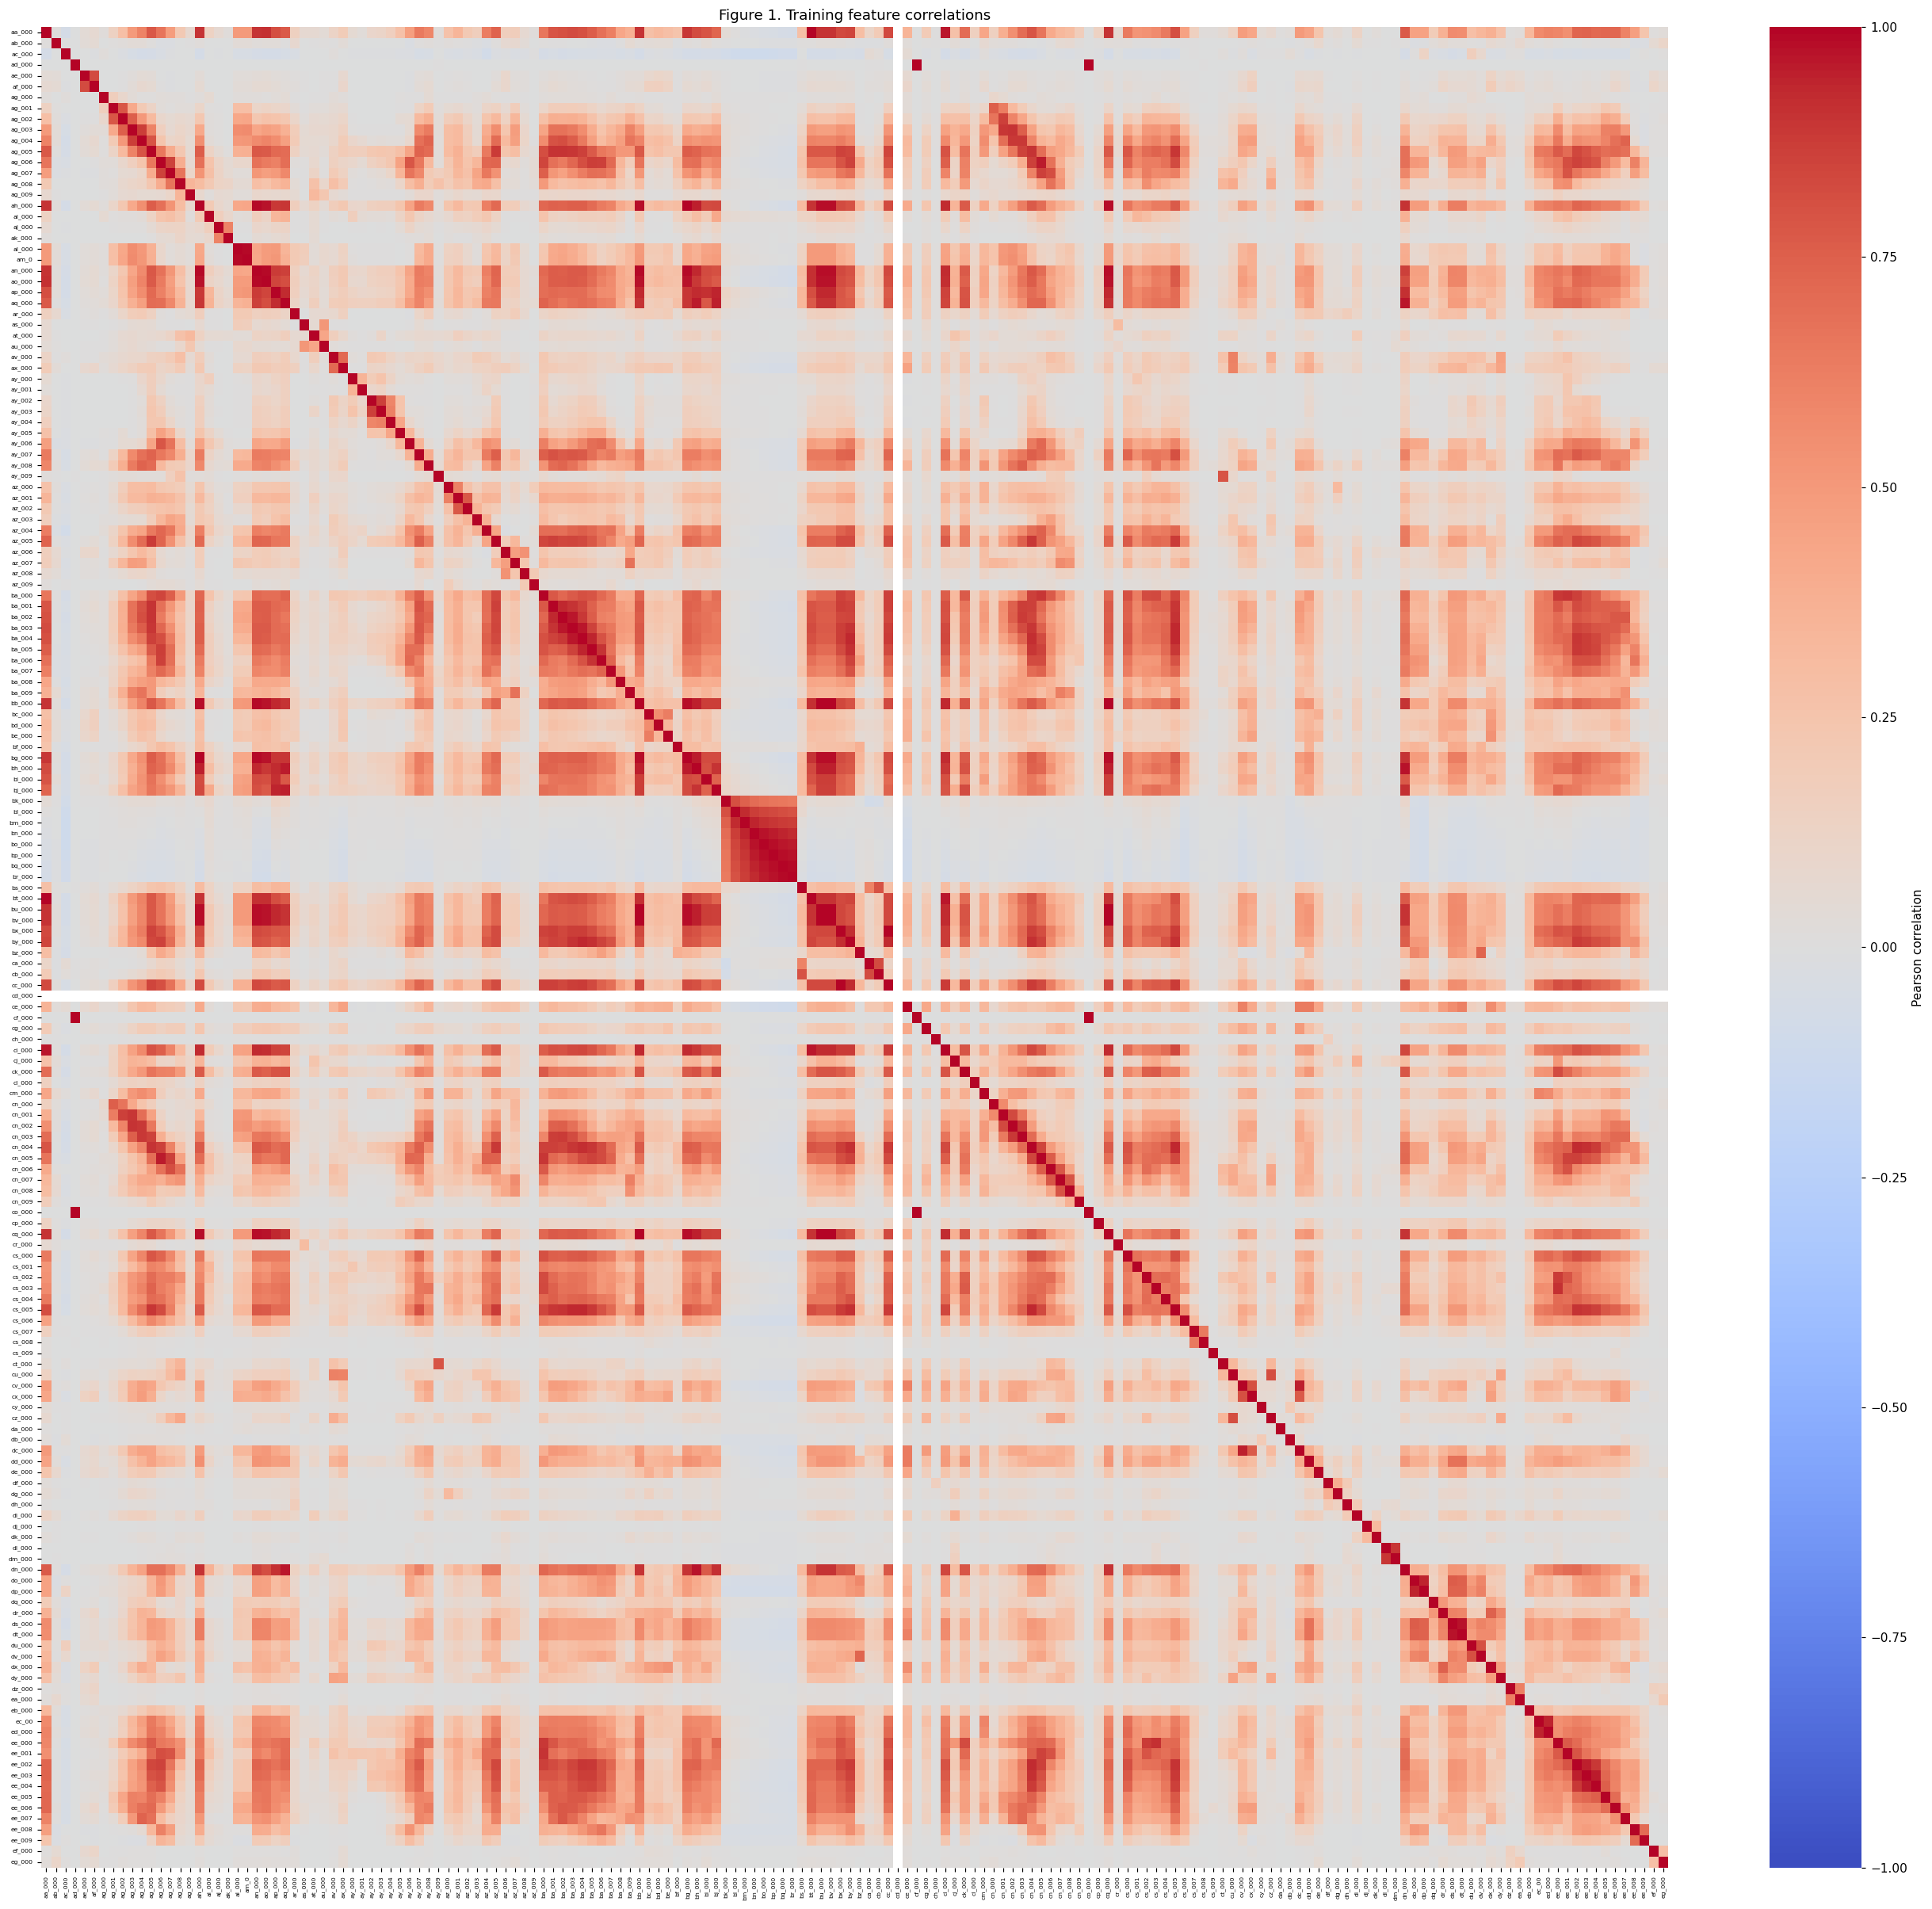

In [5]:
correlations = train_features.corr()
fig, ax = plt.subplots(figsize=(24, 22))
sns.heatmap(correlations, cmap="coolwarm", vmin=-1, vmax=1, center=0,
            xticklabels=True, yticklabels=True, ax=ax,
            cbar_kws={"label": "Pearson correlation"})
ax.tick_params(axis="both", labelsize=5)
ax.set_title("Figure 1. Training feature correlations")
fig.tight_layout()
fig.savefig(RESULT_DIR / "correlations.png", dpi=160, bbox_inches="tight")
plt.show()
correlations.to_csv(RESULT_DIR / "correlations.csv")

## 1(b)(iv) Highest-CV features

I plot the 13 features with the highest CV, since floor(sqrt(170)) = 13. All 170 features are still used for modeling. These plots use all training observations.

Scatter plots show log1p values, and box plots use symlog axes to keep extreme values from hiding the rest of the data. These changes affect only the plots.

,Mean,Sample SD,CV
cf_000,143107.534133,3.504525e+07,244.887517
co_000,143330.017733,3.504525e+07,244.507385
ad_000,143438.292067,3.504525e+07,244.322816
cs_009,770.509700,1.833278e+05,237.930554
dh_000,4392.640833,5.412441e+05,123.216097
dj_000,37.271333,4.379166e+03,117.494225
ag_000,219.157733,2.036364e+04,92.917755
as_000,125.407900,1.095219e+04,87.332500
ay_009,1149.619633,9.741156e+04,84.733735
ak_000,907.660700,7.299859e+04,80.424975


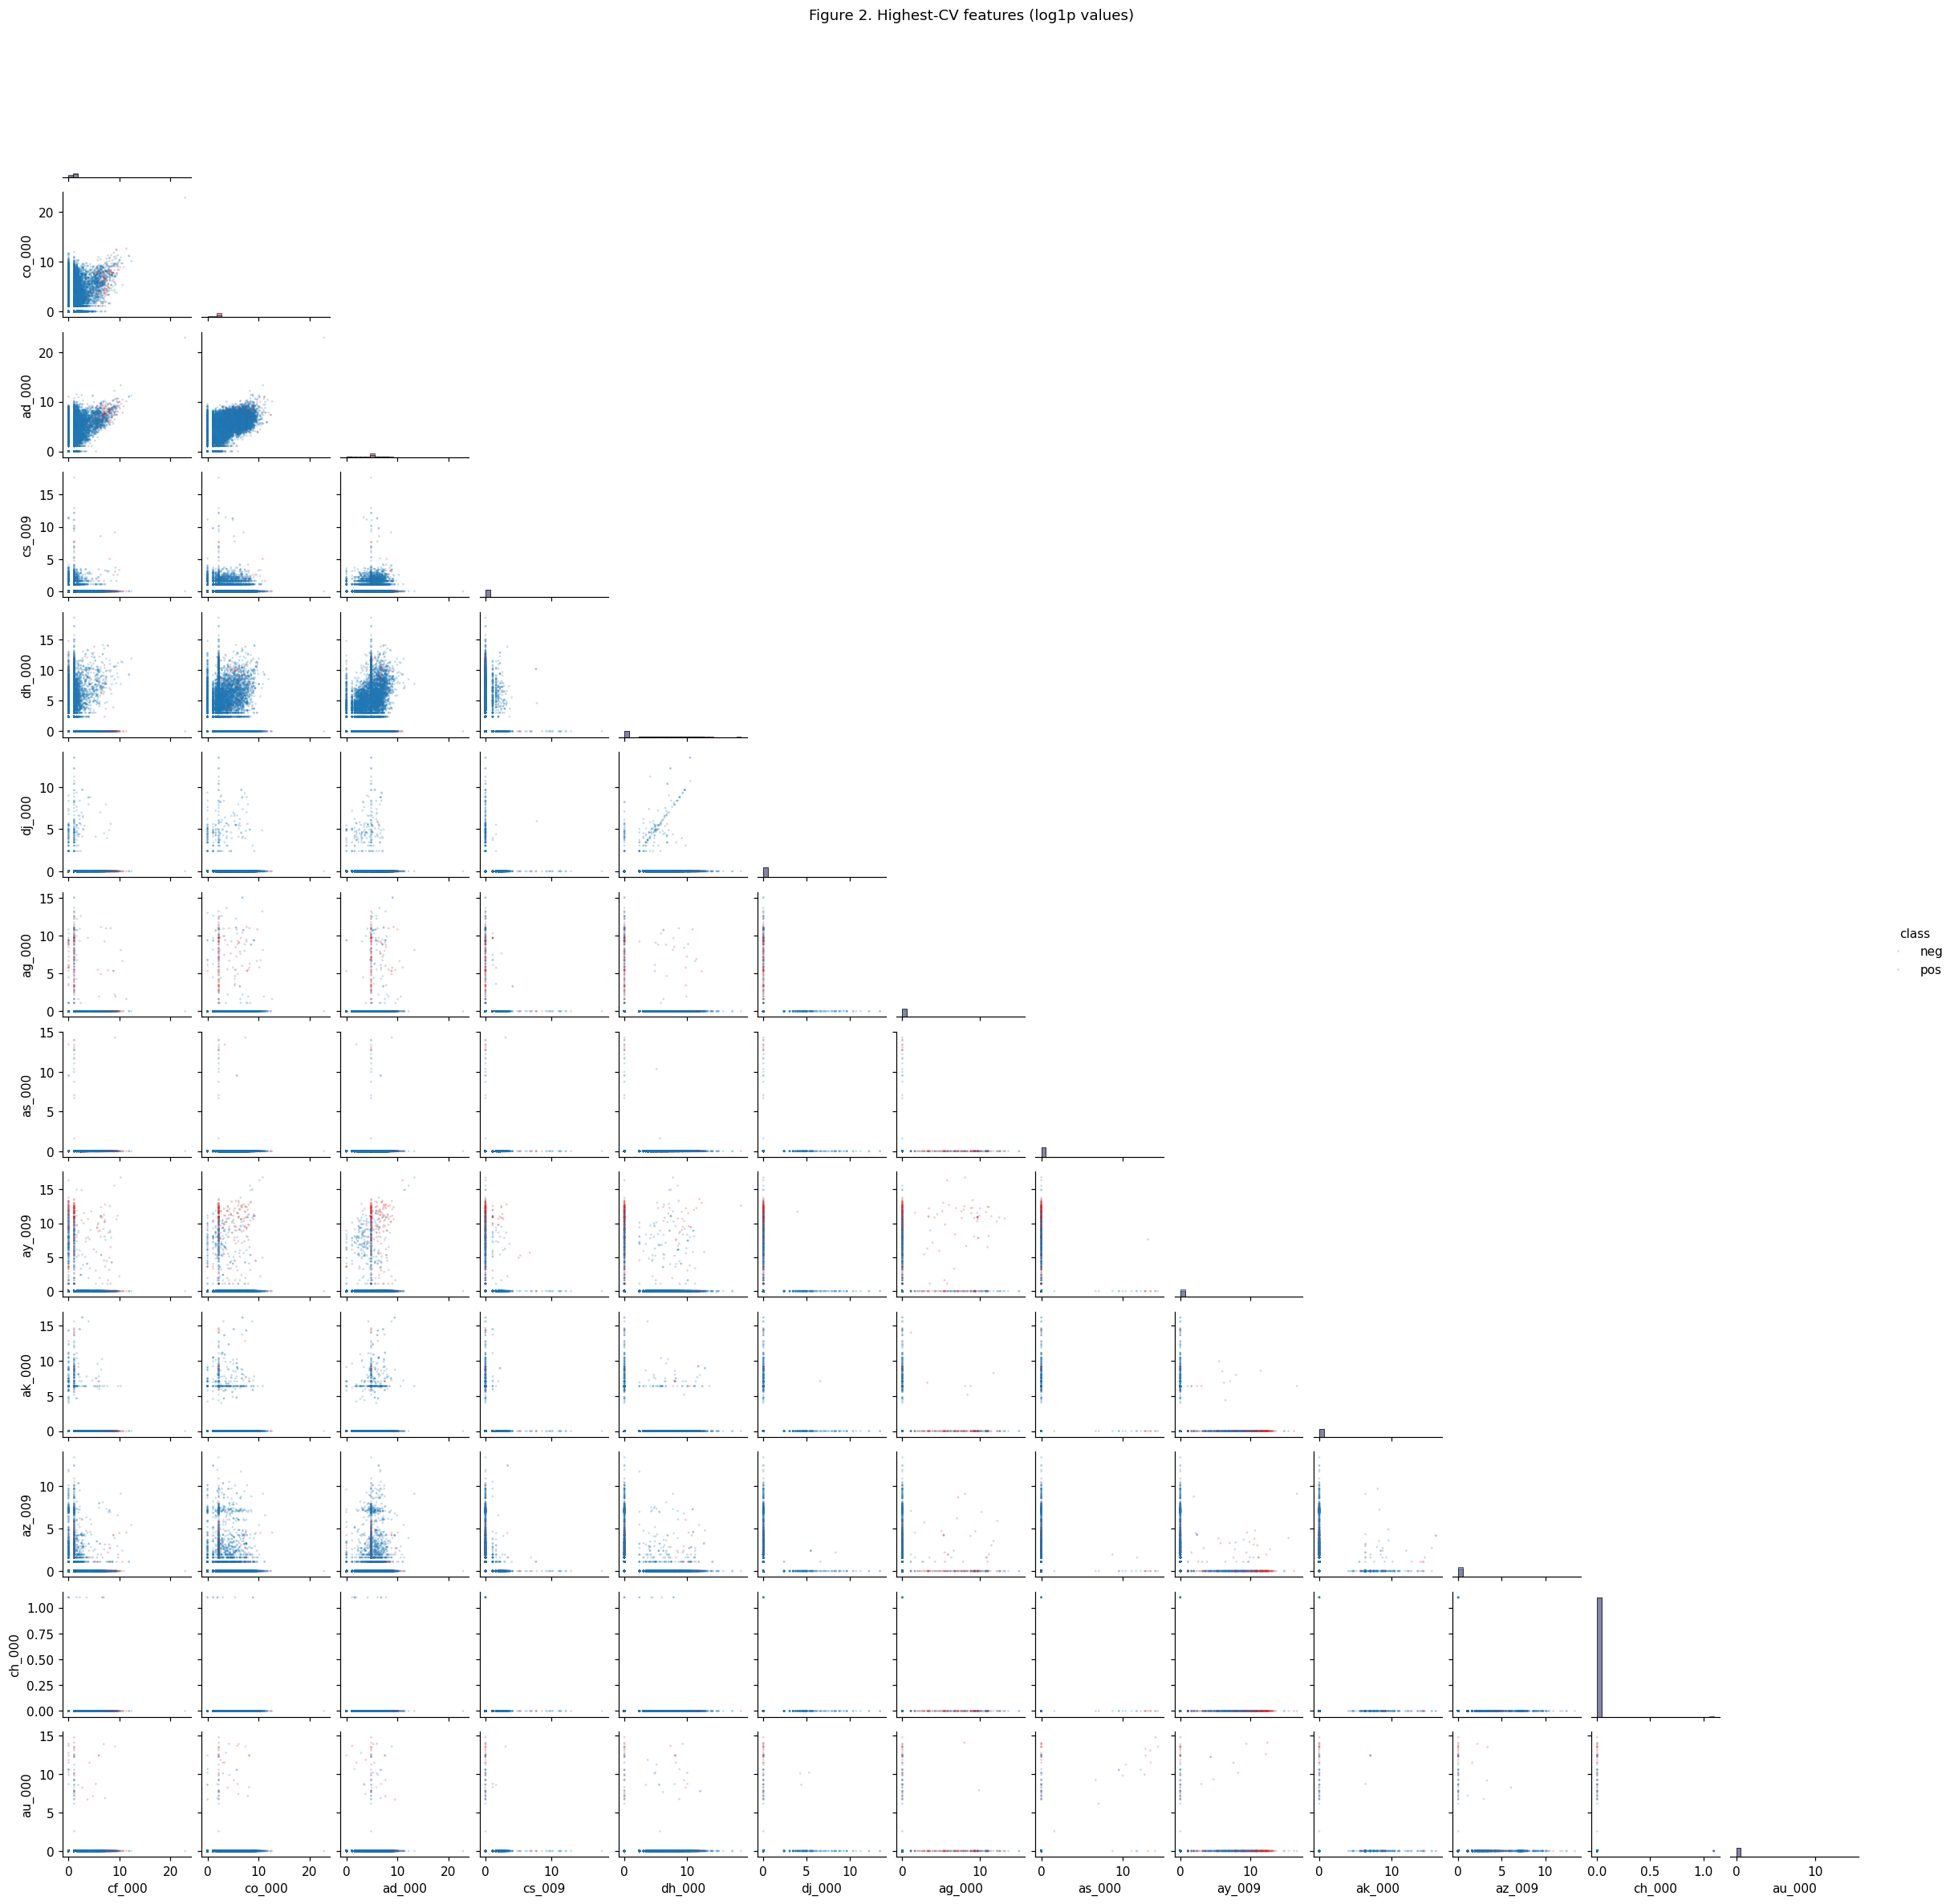

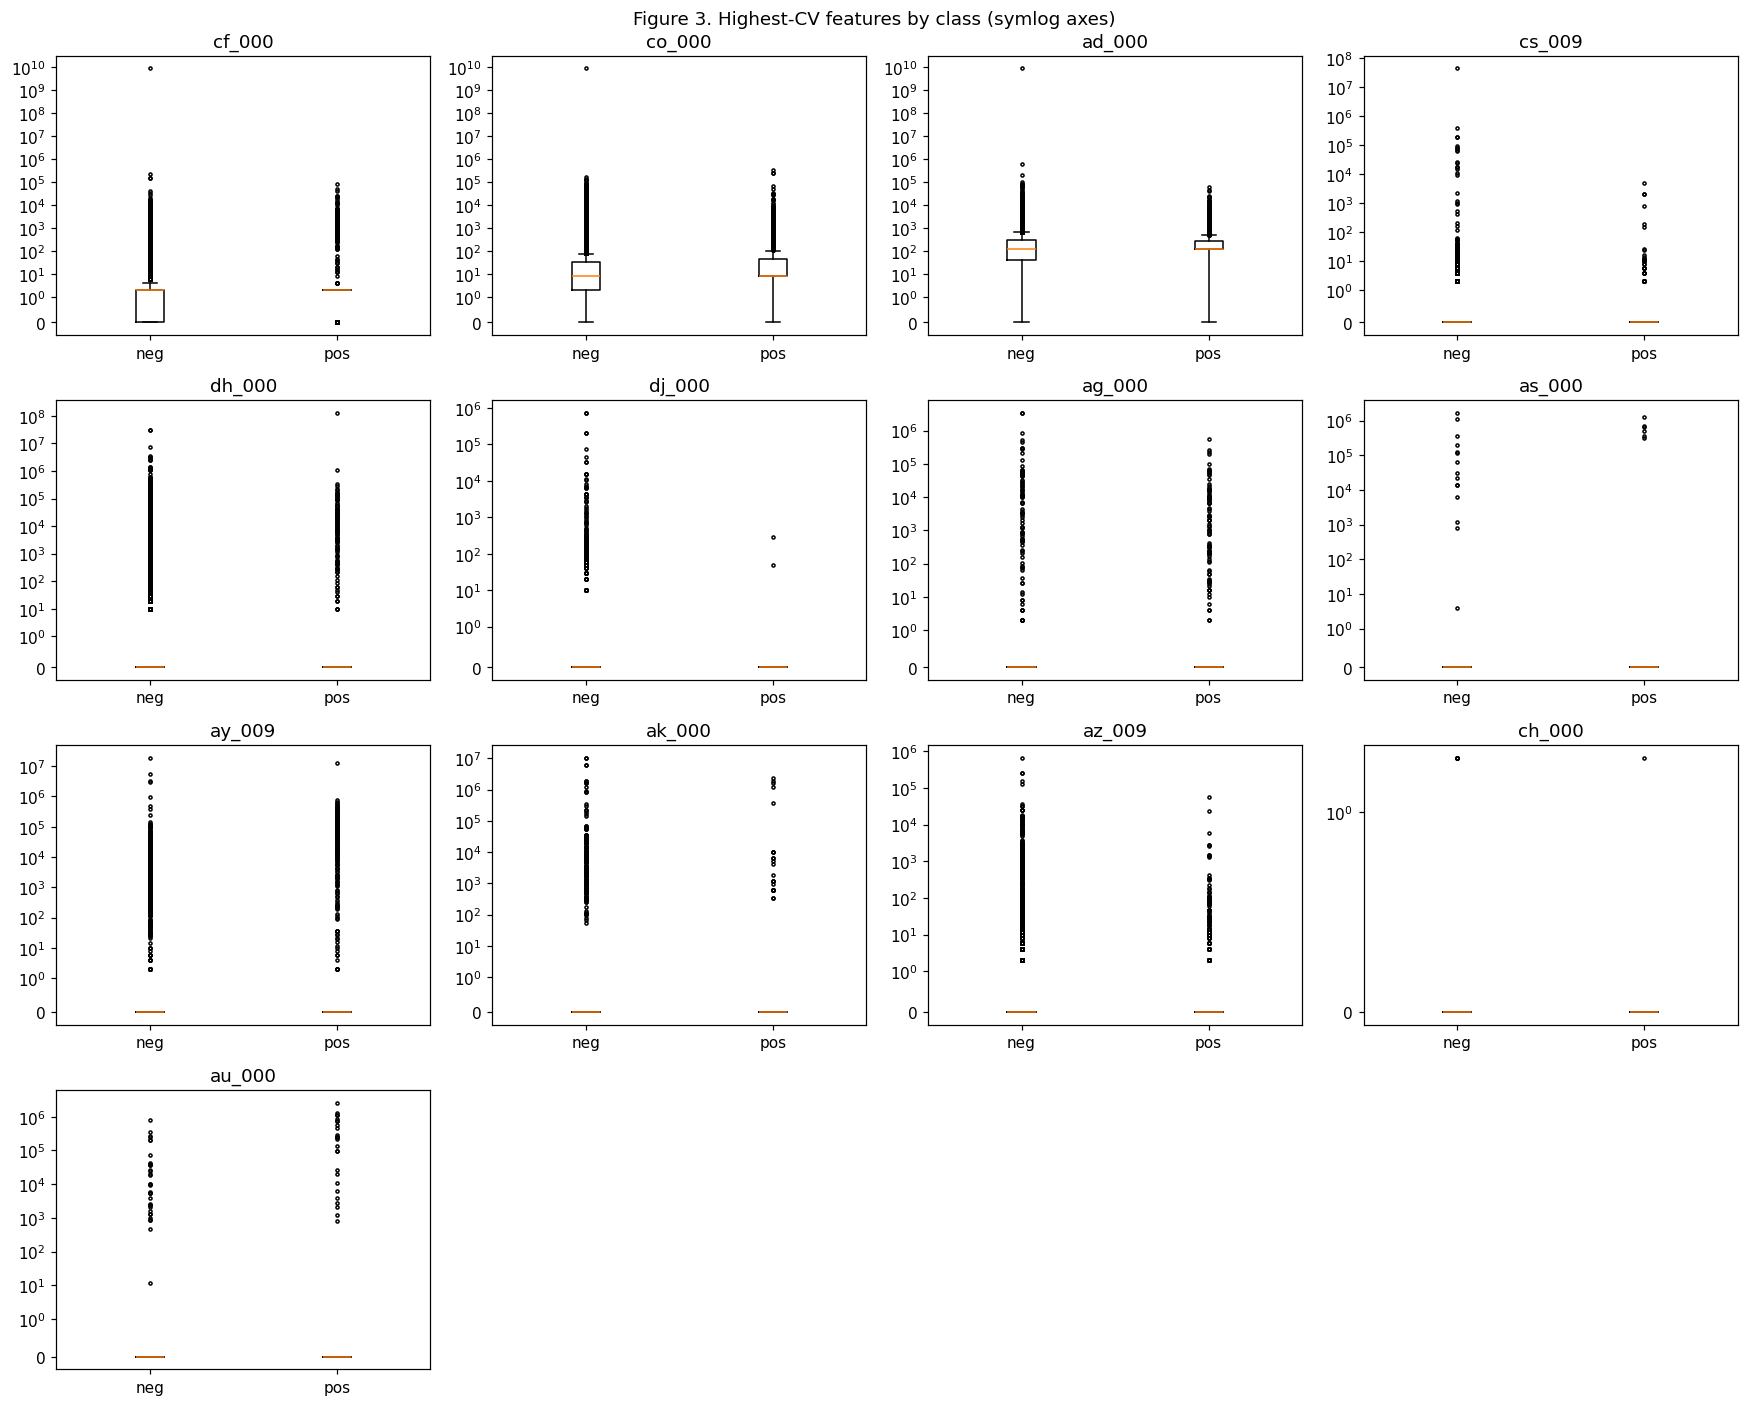

In [6]:
top_features = cv_table["CV"].dropna().head(int(np.sqrt(170))).index.tolist()
display(cv_table.loc[top_features])
plot_data = np.log1p(train_features[top_features])
plot_data["class"] = np.where(y_train == 1, "pos", "neg")
grid = sns.pairplot(
    plot_data, vars=top_features, hue="class", hue_order=["neg", "pos"],
    palette={"neg": "tab:blue", "pos": "tab:red"}, corner=True,
    diag_kind="hist", height=1.65,
    plot_kws={"s": 3, "alpha": 0.25, "linewidth": 0, "rasterized": True},
    diag_kws={"bins": 25, "stat": "density", "common_norm": False}
)
grid.fig.suptitle("Figure 2. Highest-CV features (log1p values)", y=1.01)
grid.savefig(RESULT_DIR / "top_cv_scatter.png", dpi=140, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(4, 4, figsize=(16, 13))
for ax, feature in zip(axes.flat, top_features):
    ax.boxplot([train_features.loc[y_train == 0, feature],
                train_features.loc[y_train == 1, feature]], labels=["neg", "pos"],
               flierprops={"markersize": 2})
    ax.set_title(feature)
    ax.set_yscale("symlog", linthresh=1)
for ax in list(axes.flat)[len(top_features):]:
    ax.set_visible(False)
fig.suptitle("Figure 3. Highest-CV features by class (symlog axes)")
fig.tight_layout()
fig.savefig(RESULT_DIR / "top_cv_boxplots.png", bbox_inches="tight")
plt.show()

The plots can show class overlap and unusual values, but they cannot establish statistical significance. A feature with a high CV has a large spread relative to its mean; that alone does not make it useful for predicting failure.

## 1(b)(v) Class imbalance

In [7]:
class_counts = pd.DataFrame({
    "Train": np.bincount(y_train), "Test": np.bincount(y_test)
}, index=["neg", "pos"])
display(class_counts)
print("Training positive fraction:", y_train.mean())
print("Test positive fraction:", y_test.mean())
class_counts.to_csv(RESULT_DIR / "class_counts.csv")

,Train,Test
neg,59000,15625
pos,1000,375


Training positive fraction: 0.016666666666666666
Test positive fraction: 0.0234375


The training set has 59,000 negative and 1,000 positive cases, a 59:1 ratio. The test set has 15,625 negative and 375 positive cases. Both are strongly imbalanced, so I also report positive-class recall and precision alongside the required error rate and AUC.

## 1(c) Random forest without imbalance compensation

I used 200 trees, each with bootstrap sampling and sqrt(170) candidate features per split. I left the class weights unchanged. Predictions were made with a 0.5 cutoff and ties were assigned to neg. The confusion matrices contain the actual classes in the rows and the predicted classes in the columns. The ROC curves are plotted with the positive-class probabilities.

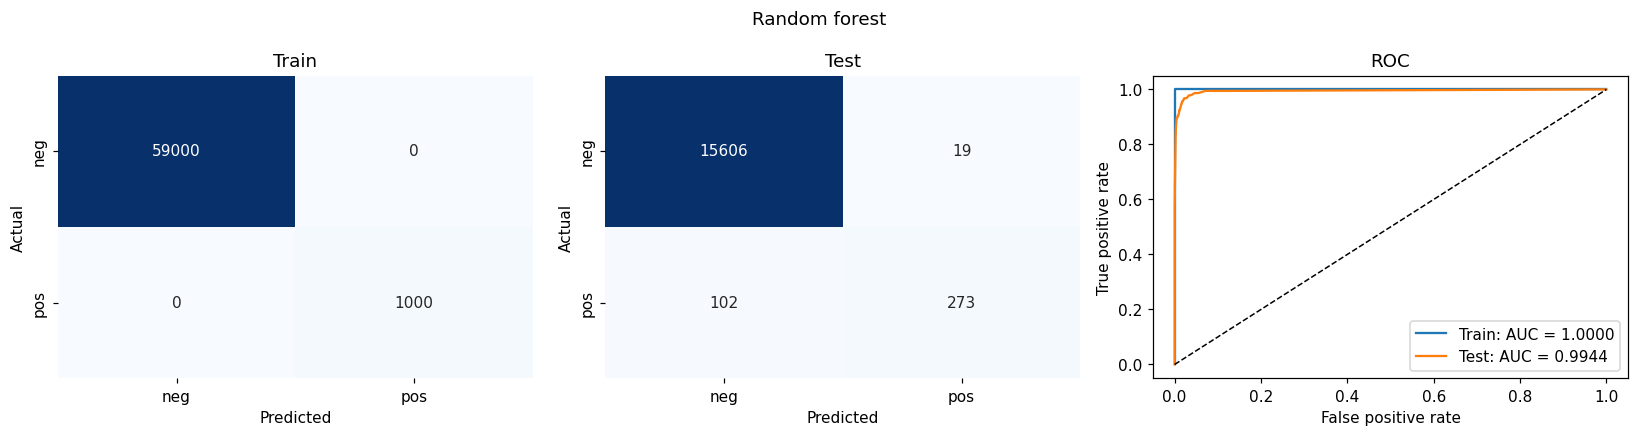

Error       AUC  Recall  Precision  Balanced accuracy  \
Model         Split                                                             
Random forest Train  0.000000  1.000000   1.000   1.000000           1.000000   
              Test   0.007563  0.994383   0.728   0.934932           0.863392   

                        TN  FP   FN    TP  
Model         Split                        
Random forest Train  59000   0    0  1000  
              Test   15606  19  102   273

,OOB error
Model,
Random forest,0.0058


In [8]:
all_scores = []
oob_scores = []
test_probabilities = pd.DataFrame({"Actual": y_test})

def score_predictions(y_true, probabilities):
    predictions = (probabilities > 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()
    return {
        "Error": 1 - accuracy_score(y_true, predictions),
        "AUC": roc_auc_score(y_true, probabilities),
        "Recall": recall_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Balanced accuracy": balanced_accuracy_score(y_true, predictions),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp
    }

def evaluate_model(name, model, train_X, test_X, filename):
    train_prob = model.predict_proba(train_X)[:, 1]
    test_prob = model.predict_proba(test_X)[:, 1]
    rows = []
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, split, labels, probabilities in [
        (axes[0], "Train", y_train, train_prob),
        (axes[1], "Test", y_test, test_prob)
    ]:
        row = {"Model": name, "Split": split, **score_predictions(labels, probabilities)}
        rows.append(row)
        all_scores.append(row)
        matrix = confusion_matrix(labels, probabilities > 0.5, labels=[0, 1])
        sns.heatmap(matrix, annot=True, fmt="d", cbar=False, cmap="Blues",
                    xticklabels=["neg", "pos"], yticklabels=["neg", "pos"], ax=ax)
        ax.set(title=split, xlabel="Predicted", ylabel="Actual")
        fpr, tpr, thresholds = roc_curve(labels, probabilities)
        axes[2].plot(fpr, tpr, label=f"{split}: AUC = {row['AUC']:.4f}")
    axes[2].plot([0, 1], [0, 1], "k--", linewidth=1)
    axes[2].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC")
    axes[2].legend()
    fig.suptitle(name)
    fig.tight_layout()
    fig.savefig(RESULT_DIR / filename, bbox_inches="tight")
    plt.show()
    display(pd.DataFrame(rows).set_index(["Model", "Split"]))
    pd.DataFrame({"Actual": y_train, "Probability": train_prob}).to_csv(
        RESULT_DIR / (Path(filename).stem + "_train_predictions.csv"), index=False
    )
    test_probabilities[name] = test_prob

def report_oob(name, forest):
    oob_prob = forest.oob_decision_function_[:, 1]
    assert np.isfinite(oob_prob).all()
    assert np.allclose(forest.oob_decision_function_.sum(axis=1), 1)
    row = {"Model": name, "OOB error": 1 - forest.oob_score_}
    oob_scores.append(row)
    display(pd.DataFrame([row]).set_index("Model"))

forest = RandomForestClassifier(
    n_estimators=200, max_features="sqrt", bootstrap=True,
    oob_score=True, class_weight=None, random_state=SEED, n_jobs=4
)
forest.fit(X_train_filled, y_train)
evaluate_model("Random forest", forest, X_train_filled, X_test_filled, "rf_plain.png")
report_oob("Random forest", forest)

The unweighted forest has test error 0.7562% and test AUC 0.9944. Its OOB error is 0.5800%, lower than the test error. It misses 102 of the 375 positive test cases, so the small overall error does not mean all failures are detected.

OOB predictions are computed only using trees whose bootstrap samples did not include the observation.
Thus, the OOB estimate is conditional on the training-median preprocessing used by the forest; it is not a validation of the entire imputation procedure.

## 1(d) Random forest with imbalance compensation

Random forests use inverse-frequency class weights, balanced sampling, or a different prediction threshold to address imbalance. I use class_weight="balanced_subsample" to calculate inverse-frequency weights for each bootstrap sample and keep all other forest settings and the cutoff constant.

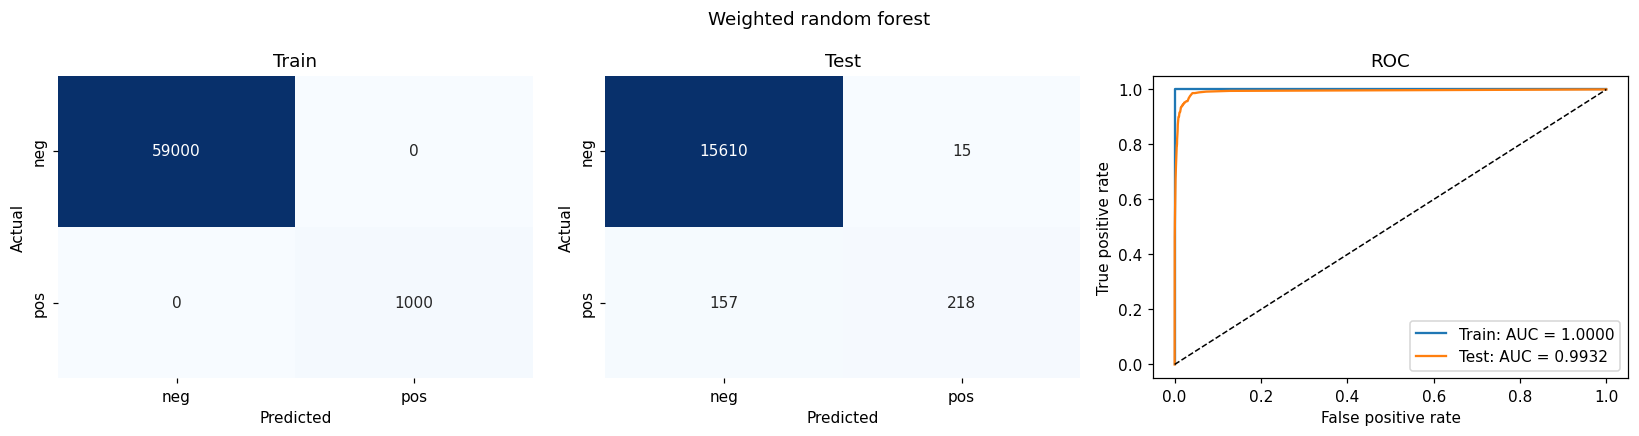

Error       AUC    Recall  Precision  \
Model                  Split                                           
Weighted random forest Train  0.00000  1.000000  1.000000   1.000000   
                       Test   0.01075  0.993161  0.581333   0.935622   

                              Balanced accuracy     TN  FP   FN    TP  
Model                  Split                                           
Weighted random forest Train           1.000000  59000   0    0  1000  
                       Test            0.790187  15610  15  157   218

,OOB error
Model,
Weighted random forest,0.00785


,Split,Error,AUC,Recall,Precision,Balanced accuracy,TN,FP,FN,TP
Model,,,,,,,,,,
Random forest,Test,0.007563,0.994383,0.728000,0.934932,0.863392,15606,19,102,273
Weighted random forest,Test,0.010750,0.993161,0.581333,0.935622,0.790187,15610,15,157,218


,OOB error
Model,
Random forest,0.00580
Weighted random forest,0.00785


In [9]:
weighted_forest = RandomForestClassifier(
    n_estimators=200, max_features="sqrt", bootstrap=True,
    oob_score=True, class_weight="balanced_subsample", random_state=SEED, n_jobs=4
)
weighted_forest.fit(X_train_filled, y_train)
evaluate_model("Weighted random forest", weighted_forest,
               X_train_filled, X_test_filled, "rf_weighted.png")
report_oob("Weighted random forest", weighted_forest)
forest_comparison = pd.DataFrame(all_scores)
display(forest_comparison[forest_comparison["Split"] == "Test"].set_index("Model"))
display(pd.DataFrame(oob_scores).set_index("Model"))

The weighted forest has test error 1.0750%, AUC 0.9932, and OOB error 0.7850%. Its OOB error is lower than its test error. Compared with the unweighted forest, its test error is higher and positive recall is lower (58.13% versus 72.80%). False positives change from 19 to 15, and false negatives from 102 to 157. Class weighting changes the fitting objective, but does not guarantee better recall at a fixed cutoff.

## 1(e) XGBoost without imbalance compensation

I use XGBoost with binary logistic loss and L1 penalty. Search over reg_alpha = 0, 0.01, 0.1, 1, 10, 100 with five-fold stratified CV. Other parameters are set to 200 trees, depth of 4, learning rate of 0.1 and reg_lambda = 0. No class weights or resampling used here. Select the lowest mean validation misclassification rate. In case of ties select the smaller alpha.

The tree booster of XGBoost uses single-feature splits and penalized leaf scores. It does not fit a separate L1 logistic regression at each node (as an oblique logistic model tree would do).

Note that both XGBoost implementations use training-fitted standardization in order to prevent that the distances in SMOTE are dominated by the feature units. The CV error is an estimate of the tuning error and can be somewhat optimistic after selecting the optimal alpha.

Completed fold 1/5, SMOTE=False


Completed fold 2/5, SMOTE=False


Completed fold 3/5, SMOTE=False


Completed fold 4/5, SMOTE=False


Completed fold 5/5, SMOTE=False


,alpha,CV_error,SD_error,CV_AUC,CV_recall
0,0.00,0.005967,0.000728,0.988746,0.733
1,0.01,0.005817,0.000563,0.988774,0.739
2,0.10,0.005883,0.000366,0.988373,0.740
3,1.00,0.005933,0.000393,0.989519,0.730
4,10.00,0.006617,0.000466,0.990026,0.700
5,100.00,0.011200,0.000509,0.984060,0.366


Selected alpha: 0.01


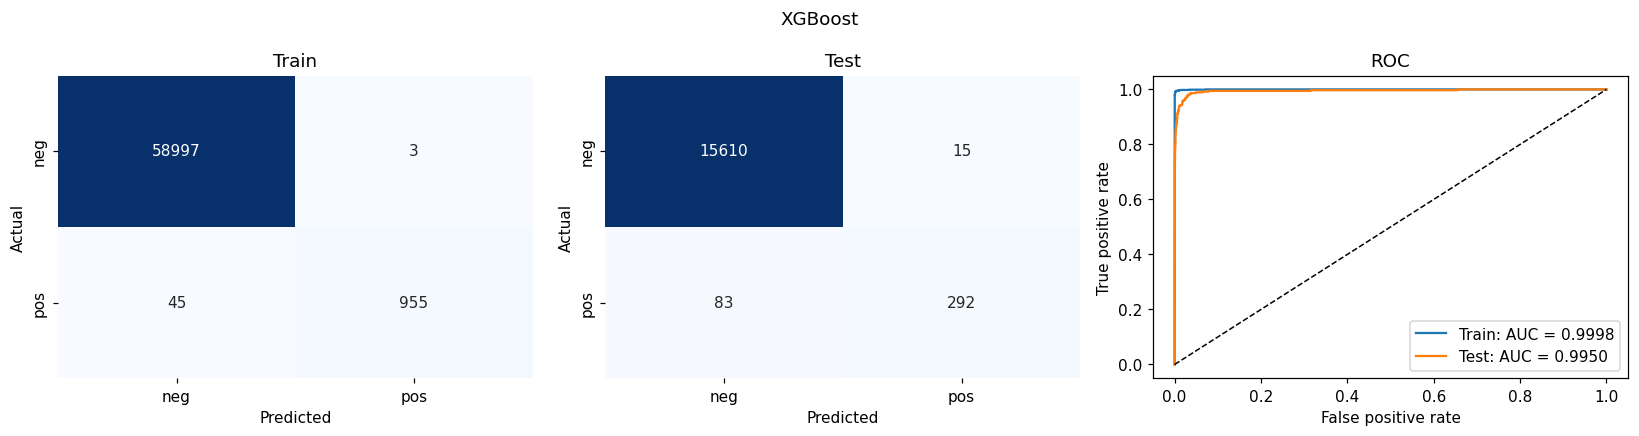

Error       AUC    Recall  Precision  Balanced accuracy  \
Model   Split                                                               
XGBoost Train  0.000800  0.999837  0.955000   0.996868           0.977475   
        Test   0.006125  0.994988  0.778667   0.951140           0.888853   

                  TN  FP  FN   TP  
Model   Split                      
XGBoost Train  58997   3  45  955  
        Test   15610  15  83  292

In [10]:
alphas = [0, 0.01, 0.1, 1, 10, 100]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(cv.split(X_train, y_train))

def make_booster(alpha):
    return XGBClassifier(
        objective="binary:logistic", eval_metric="logloss", booster="gbtree",
        n_estimators=200, max_depth=4, learning_rate=0.1,
        reg_alpha=alpha, reg_lambda=0, scale_pos_weight=1,
        tree_method="hist", subsample=1, colsample_bytree=1,
        random_state=SEED, n_jobs=4
    )

def tune_booster(use_smote, filename):
    rows = []
    for fold_number, (train_rows, validation_rows) in enumerate(folds, start=1):
        fold_train = X_train.iloc[train_rows]
        fold_validation = X_train.iloc[validation_rows]
        assert not fold_train.isna().all().any()
        assert not fold_validation.isna().all().any()
        train_values = SimpleImputer(strategy="median").fit_transform(fold_train)
        validation_values = SimpleImputer(strategy="median").fit_transform(fold_validation)
        scaler = StandardScaler()
        train_values = scaler.fit_transform(train_values).astype(np.float32)
        validation_values = scaler.transform(validation_values).astype(np.float32)
        train_labels = y_train[train_rows]
        validation_labels = y_train[validation_rows]
        if use_smote:
            sampler = SMOTE(random_state=SEED, k_neighbors=5)
            with threadpool_limits(limits=4):
                train_values, train_labels = sampler.fit_resample(train_values, train_labels)
            assert np.bincount(train_labels).tolist() == [47200, 47200]
        for alpha in alphas:
            model = make_booster(alpha)
            model.fit(train_values, train_labels)
            probabilities = model.predict_proba(validation_values)[:, 1]
            rows.append({"Fold": fold_number, "alpha": alpha,
                         "Fit rows": len(train_labels),
                         **score_predictions(validation_labels, probabilities)})
        print(f"Completed fold {fold_number}/5, SMOTE={use_smote}", flush=True)

    fold_results = pd.DataFrame(rows)
    summary = fold_results.groupby("alpha").agg(
        CV_error=("Error", "mean"), SD_error=("Error", "std"),
        CV_AUC=("AUC", "mean"), CV_recall=("Recall", "mean")
    ).reset_index()
    best = summary.sort_values(["CV_error", "alpha"]).iloc[0]
    fold_results.to_csv(RESULT_DIR / filename, index=False)
    display(summary)
    print("Selected alpha:", best["alpha"])
    return best, summary

best_plain, cv_plain = tune_booster(False, "xgb_plain_cv.csv")
booster_scaler = StandardScaler()
X_train_scaled = booster_scaler.fit_transform(X_train_filled).astype(np.float32)
X_test_scaled = booster_scaler.transform(X_test_filled).astype(np.float32)
plain_booster = make_booster(float(best_plain["alpha"]))
plain_booster.fit(X_train_scaled, y_train)
evaluate_model("XGBoost", plain_booster, X_train_scaled, X_test_scaled, "xgb_plain.png")

Without SMOTE, CV chooses alpha = 0.01. The five-fold CV error is 0.5817%, compared with test error 0.6125%. Test AUC is 0.9950.

## 1(f) SMOTE and XGBoost

The correct way to do this is to split the original training data into folds first, and then apply SMOTE within each training fold. If you apply SMOTE first, then related original and synthetic samples can end up in both the training and validation folds. The validation and test sets will have the original class proportions.

I use all 60,000 training cases. In the final fit, SMOTE increases the positive class to 59,000, giving 118,000 training cases. Reported training metrics use the original 60,000 observations, not synthetic samples.

Completed fold 1/5, SMOTE=True


Completed fold 2/5, SMOTE=True


Completed fold 3/5, SMOTE=True


Completed fold 4/5, SMOTE=True


Completed fold 5/5, SMOTE=True


,alpha,CV_error,SD_error,CV_AUC,CV_recall
0,0.00,0.013183,0.001278,0.987341,0.876
1,0.01,0.013183,0.001814,0.986554,0.869
2,0.10,0.013317,0.001472,0.986987,0.885
3,1.00,0.013100,0.001956,0.987365,0.873
4,10.00,0.014250,0.001917,0.987289,0.876
5,100.00,0.023383,0.002485,0.986975,0.916


Selected alpha: 1.0
SMOTE class counts: [59000 59000]


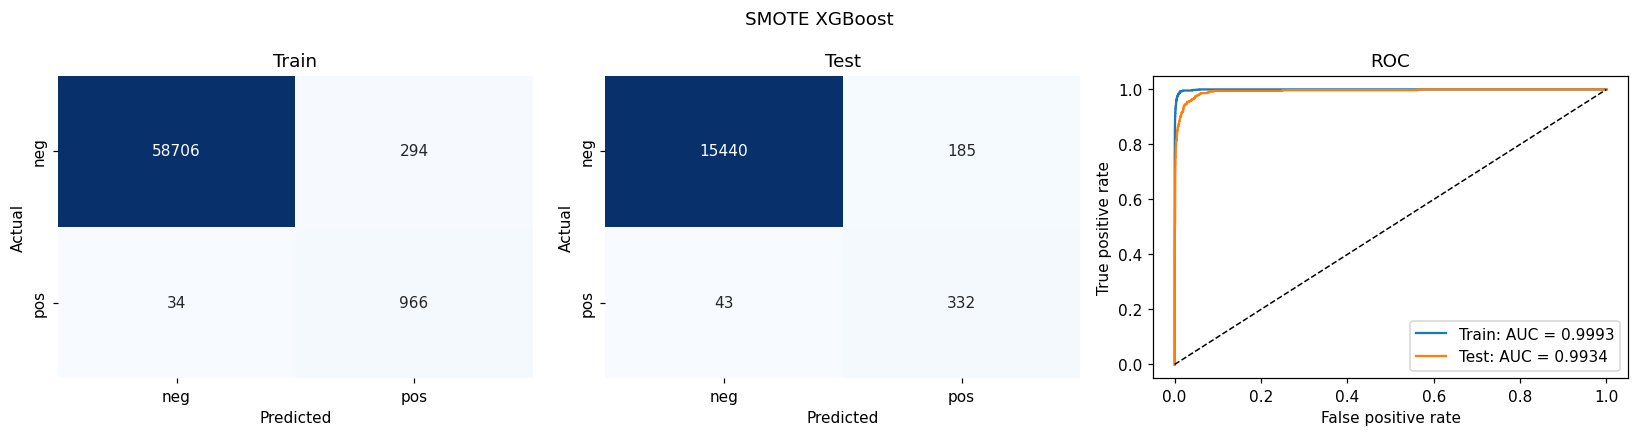

Error       AUC    Recall  Precision  \
Model         Split                                            
SMOTE XGBoost Train  0.005467  0.999273  0.966000   0.766667   
              Test   0.014250  0.993382  0.885333   0.642166   

                     Balanced accuracy     TN   FP  FN   TP  
Model         Split                                          
SMOTE XGBoost Train           0.980508  58706  294  34  966  
              Test            0.936747  15440  185  43  332

,Split,Error,AUC,Recall,Precision,Balanced accuracy,TN,FP,FN,TP
Model,,,,,,,,,,
Random forest,Test,0.007563,0.994383,0.728000,0.934932,0.863392,15606,19,102,273
Weighted random forest,Test,0.010750,0.993161,0.581333,0.935622,0.790187,15610,15,157,218
XGBoost,Test,0.006125,0.994988,0.778667,0.951140,0.888853,15610,15,83,292
SMOTE XGBoost,Test,0.014250,0.993382,0.885333,0.642166,0.936747,15440,185,43,332


,Model,alpha,CV error,Error
0,XGBoost,0.01,0.005817,0.006125
1,SMOTE XGBoost,1.00,0.013100,0.014250


In [11]:
best_smote, cv_smote = tune_booster(True, "xgb_smote_cv.csv")
sampler = SMOTE(random_state=SEED, k_neighbors=5)
with threadpool_limits(limits=4):
    X_smote, y_smote = sampler.fit_resample(X_train_scaled, y_train)
assert X_smote.shape == (118000, 170)
assert np.bincount(y_smote).tolist() == [59000, 59000]
print("SMOTE class counts:", np.bincount(y_smote))
smote_booster = make_booster(float(best_smote["alpha"]))
smote_booster.fit(X_smote, y_smote)
evaluate_model("SMOTE XGBoost", smote_booster, X_train_scaled, X_test_scaled, "xgb_smote.png")

comparison = pd.DataFrame(all_scores)
comparison.to_csv(RESULT_DIR / "model_scores.csv", index=False)
test_probabilities.to_csv(RESULT_DIR / "test_probabilities.csv", index=False)
pd.DataFrame(oob_scores).to_csv(RESULT_DIR / "oob_scores.csv", index=False)
validation_comparison = pd.DataFrame([
    {"Model": "XGBoost", "alpha": best_plain["alpha"], "CV error": best_plain["CV_error"]},
    {"Model": "SMOTE XGBoost", "alpha": best_smote["alpha"], "CV error": best_smote["CV_error"]}
])
test_rows = comparison[comparison["Split"] == "Test"]
display(test_rows.set_index("Model"))
display(validation_comparison.merge(test_rows[["Model", "Error"]], on="Model"))
validation_comparison.to_csv(RESULT_DIR / "selected_parameters.csv", index=False)

With SMOTE, CV chooses alpha = 1. CV error is 1.3100%, and test error is 1.4250%; test AUC is 0.9934. Compared with the uncompensated XGBoost model, test error is higher and recall is higher (88.53% versus 77.87%). False negatives change from 83 to 43, while false positives change from 15 to 185.

## 2. ISLR 6.6.3

As s increases, the constraint $\sum_j |\beta_j|\leq s$ becomes less restrictive.

**(a) iv.** Training RSS decreases or stays the same because the feasible set expands. Once the least-squares solution is allowed, it stays constant.

**(b) ii.** Test RSS typically decreases at first and then increases as the model moves from underfitting toward overfitting. This is the usual bias-variance pattern, not a guarantee for every data set.

**(c) iii.** Variance generally increases as the model becomes more flexible.

**(d) iv.** Squared bias generally decreases as the constraint relaxes.

**(e) v.** Irreducible error stays constant because changing s does not change the noise in the data.

## 3. ISLR 6.6.5

Let $x_i=x_{i1}=x_{i2}$ and $t=\beta_1+\beta_2$. The intercept is zero because the predictors and response are centered.

**(a)** Ridge solves
$$\min_{\beta_1,\beta_2}\;\sum_{i=1}^2[y_i-x_i(\beta_1+\beta_2)]^2+\lambda(\beta_1^2+\beta_2^2).$$

**(b)** For fixed t, RSS does not depend on how t is split between the coefficients. Since
$$\beta_1^2+\beta_2^2=\frac{t^2+(\beta_1-\beta_2)^2}{2},$$
the penalty is smallest when $\hat\beta_1=\hat\beta_2=t/2$. For $\lambda>0$, the ridge solution is unique.

**(c)** LASSO solves
$$\min_{\beta_1,\beta_2}\;\sum_{i=1}^2[y_i-x_i(\beta_1+\beta_2)]^2+\lambda(|\beta_1|+|\beta_2|).$$

**(d)** For $\lambda>0$, the triangle inequality gives $|\beta_1|+|\beta_2|\geq|t|$, with equality when the coefficients have the same sign or one is zero. Therefore, if the optimal sum $t^*\ne0$, every pair
$$\hat\beta_1=u t^*,\qquad \hat\beta_2=(1-u)t^*,\qquad 0\leq u\leq1$$
has the same predictions and penalty. These are infinitely many solutions, including putting the entire coefficient on either predictor.

For $A=\sum_i x_i^2>0$ and $B=\sum_i x_i y_i$,
$$t^*=\frac{\operatorname{sign}(B)(|B|-\lambda/2)_+}{A}.$$
If the penalty is large enough that $t^*=0$ and $\lambda>0$, the only solution is $(0,0)$. Thus the nonuniqueness applies to a nonzero fitted sum; it does not hold for every possible penalty.

## 4. ISLR 8.4.5

Six of the ten trees give P(Red) greater than 0.5, so majority voting predicts **Red**.

The average probability is (0.1 + 0.15 + 0.2 + 0.2 + 0.55 + 0.6 + 0.6 + 0.65 + 0.7 + 0.75) / 10 = **0.45**. Averaging probabilities therefore predicts **Green**.

## 5. ISLR 9.7.3

**(a)-(b)** The observations and optimal separating line are plotted below. The line is
$$0.5-X_1+X_2=0,\qquad X_2=X_1-0.5.$$
The closest parallel faces of the class convex hulls lie on $X_2=X_1$ and $X_2=X_1-1$. The separating line lies halfway between them.

**(c)** Classify an observation as Red if $0.5-X_1+X_2>0$, and Blue otherwise. One choice is $\beta_0=0.5$, $\beta_1=-1$, and $\beta_2=1$.

**(d)** The distance from the boundary to either margin is $M=0.5/\sqrt{2}\approx0.3536$. The full width between the margins is $1/\sqrt{2}\approx0.7071$. Dividing all three coefficients by $\sqrt{2}$ gives the unit-normal form.

**(e)** The support vectors are observations **2, 3, 5, and 6**, at (2,2), (4,4), (2,1), and (4,3).

**(f)** Observation 7, (4,1), lies well beyond the Blue margin. A small movement that leaves it outside the margin does not change the support vectors or optimal boundary.

**(g)** The line $X_2=X_1-0.25$ also separates the classes, but its minimum distance to a point is only $0.25/\sqrt{2}$, so it is not optimal.

**(h)** Add a Blue observation at (2,3). It lies inside the Red triangle formed by observations 2, 3, and 4, so no straight line can separate the two classes.

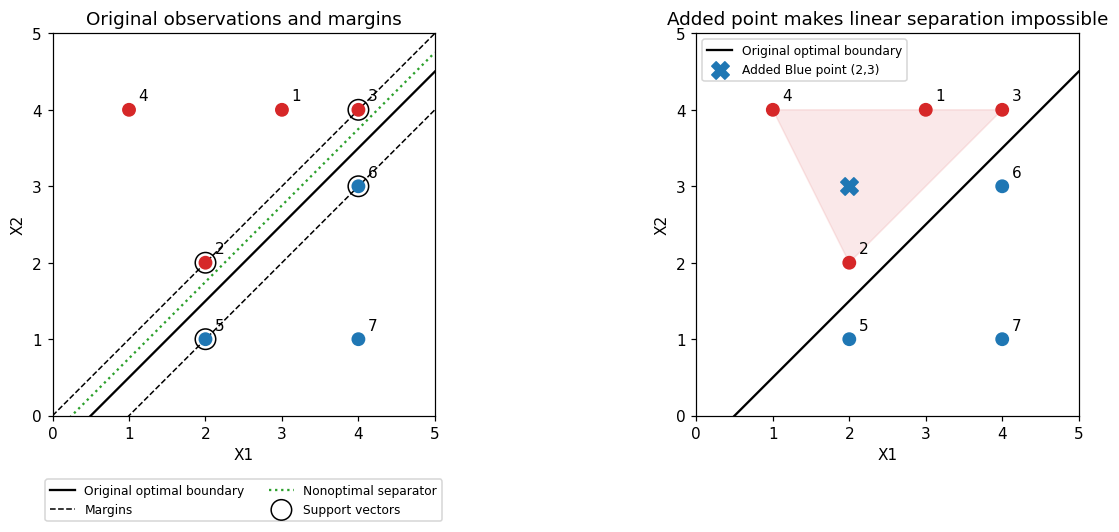

In [12]:
points = np.array([[3, 4], [2, 2], [4, 4], [1, 4], [2, 1], [4, 3], [4, 1]])
colors = ["tab:red"] * 4 + ["tab:blue"] * 3
support = [1, 2, 4, 5]
x_line = np.linspace(0, 5, 200)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax in axes:
    ax.scatter(points[:, 0], points[:, 1], c=colors, s=65, zorder=3)
    for number, (x, y) in enumerate(points, start=1):
        ax.annotate(str(number), (x, y), xytext=(6, 6), textcoords="offset points")
    ax.plot(x_line, x_line - 0.5, "k-", label="Original optimal boundary")
    ax.set(xlabel="X1", ylabel="X2", xlim=(0, 5), ylim=(0, 5))
    ax.set_aspect("equal")

axes[0].plot(x_line, x_line, "k--", linewidth=1, label="Margins")
axes[0].plot(x_line, x_line - 1, "k--", linewidth=1)
axes[0].plot(x_line, x_line - 0.25, color="tab:green", linestyle=":", label="Nonoptimal separator")
axes[0].scatter(points[support, 0], points[support, 1], s=180,
                facecolors="none", edgecolors="black", label="Support vectors")
axes[0].set_title("Original observations and margins")
axes[0].legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
triangle = points[[1, 2, 3, 1]]
axes[1].fill(triangle[:, 0], triangle[:, 1], color="tab:red", alpha=0.1)
axes[1].scatter([2], [3], c="tab:blue", marker="X", s=130, label="Added Blue point (2,3)", zorder=4)
axes[1].set_title("Added point makes linear separation impossible")
axes[1].legend(fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig(RESULT_DIR / "maximal_margin.png", bbox_inches="tight")
plt.show()

## References

- Homework 6 handout and the supplied APS data description.
- [Scikit-learn: missing-value imputation](https://scikit-learn.org/stable/modules/impute.html).
- [Scikit-learn: RandomForestClassifier](https://scikit-learn.org/1.3/modules/generated/sklearn.ensemble.RandomForestClassifier.html).
- [Imbalanced-learn: resampling and data leakage](https://imbalanced-learn.org/stable/common_pitfalls.html).
- [XGBoost parameters](https://xgboost.readthedocs.io/en/stable/parameter.html).
- James, Witten, Hastie, and Tibshirani, *An Introduction to Statistical Learning*, second edition: Exercises 6.6.3, 6.6.5, 8.4.5, and 9.7.3.